In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np

# seed fisso per riproducibilità
rng = np.random.default_rng(1) 

# Parametri
N_bit = 100000
SNR_dB = 8

# Sorgente
bits = rng.integers(0, 2, N_bit)

# Mappatura antipodale
simboli = 2 * bits.astype(int) - 1 

# Rumore AWGN
SNR = 10 ** (SNR_dB / 10)          # conversione da dB a scala lineare
sigma = np.sqrt(1 / (2 * SNR))     # deviazione standard

# rumore = sigma * np.random.randn(N_bit)
rumore = sigma * rng.standard_normal(N_bit)

# Segnale ricevuto
ricevuti = simboli + rumore

bit_ricevuti = (ricevuti > 0).astype(int)

print(bit_ricevuti)
print(len(bit_ricevuti))

[0 1 1 ... 0 0 1]
100000


Avvio simulazione per SNR = 10dB e Lc = 64...


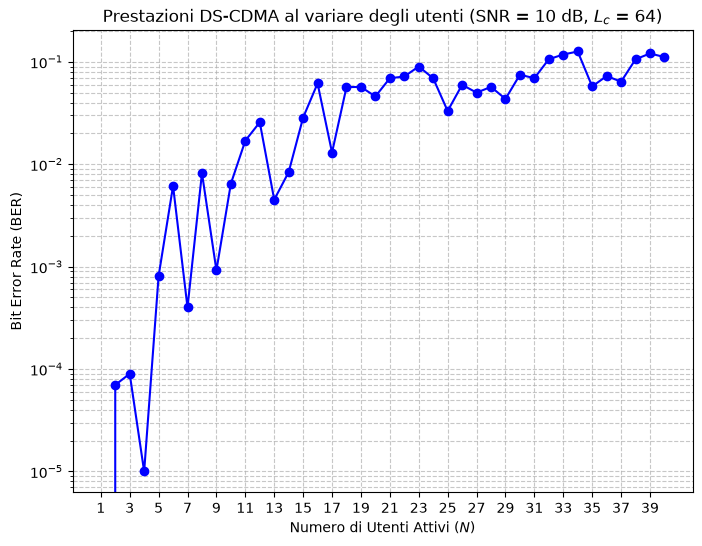

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Seed fisso per riproducibilità
rng = np.random.default_rng(42)

# --- PARAMETRI FISSI ---
N_bit = 100000       # Bit per utente
SNR_dB = 10         # Fissiamo l'SNR a 10 dB
Lc = 64             # Processing Gain (es. 32)
max_users = 40      # Numero massimo di utenti da simulare

# Calcolo del rumore (fisso per ogni iterazione)
SNR = 10 ** (SNR_dB / 10)
sigma = np.sqrt(Lc / (2 * SNR))

# Vettori per salvare i risultati
utenti_array = np.arange(1, max_users + 1)
ber_array = np.zeros(max_users)

print(f"Avvio simulazione per SNR = {SNR_dB}dB e Lc = {Lc}...")

# --- CICLO SUL NUMERO DI UTENTI ---
for i, num_users in enumerate(utenti_array):
    
    # 1. Sorgente e codici
    bits = rng.integers(0, 2, (num_users, N_bit))
    simboli = 2 * bits.astype(int) - 1
    codici = 2 * rng.integers(0, 2, (num_users, Lc)) - 1
    
    # 2. Trasmettitore (Canale Condiviso)
    segnale_canale = np.zeros(N_bit * Lc)
    for u in range(num_users):
        segnale_canale += np.kron(simboli[u], codici[u])
        
    # 3. Canale (AWGN)
    rumore = sigma * rng.standard_normal(len(segnale_canale))
    ricevuti = segnale_canale + rumore
    
    # 4. Ricevitore (target: Utente 0)
    ricevuti_blocchi = ricevuti.reshape((N_bit, Lc))
    despread = np.sum(ricevuti_blocchi * codici[0], axis=1) / Lc
    
    # 5. Calcolo BER
    bit_ricevuti = (despread > 0).astype(int)
    errori = np.sum(bits[0] != bit_ricevuti)
    ber = errori / N_bit
    ber_array[i] = ber

# --- PLOT DEI RISULTATI ---
plt.figure(figsize=(8, 6))
# Usiamo scala semilogaritmica (tipica per le curve di BER)
plt.semilogy(utenti_array, ber_array, marker='o', linestyle='-', color='b')

plt.title(f'Prestazioni DS-CDMA al variare degli utenti (SNR = {SNR_dB} dB, $L_c$ = {Lc})')
plt.xlabel('Numero di Utenti Attivi ($N$)')
plt.ylabel('Bit Error Rate (BER)')
plt.grid(True, which="both", ls="--", alpha=0.7)
plt.xticks(np.arange(1, max_users + 1, step=2))

plt.show()